In [1]:
%pip install plotly polars

Note: you may need to restart the kernel to use updated packages.


In [1]:
from pathlib import Path
import polars as pl
import plotly.express as px
import re

FOLDER_PROYEK = Path("/home/jovyan/work")

DATA_PATH = (
    FOLDER_PROYEK
    / "data/processed/EmoTweetID_clean.csv"
)

print("File data bersih ditemukan:", DATA_PATH.is_file())

File data bersih ditemukan: True


In [2]:
df = pl.read_csv(DATA_PATH)

print("Jumlah baris:", f"{df.height:,}")
print("Jumlah kolom:", df.width)
print("Nama kolom:", df.columns)

df.head()

Jumlah baris: 3,126,987
Jumlah kolom: 2
Nama kolom: ['', 'tweet']


,tweet
i64,str
46713,"""Fasis yang baik adalah fasis y…"
47340,"""Rinnegan (mais le sharingan )"""
47584,"""+ Sirkelmu sampah, mas"""
47402,"""Page 366 of 366 Sudah bertahan…"
47180,"""Kecanduan My Lucture My Husban…"


In [4]:
from collections import Counter

teks = df["tweet"].drop_nulls().to_list()

kata_semua = []

for tweet in teks:
    kata = re.findall(r"\b[a-zA-ZÀ-ÿ]+\b", tweet.lower())
    kata_semua.extend(kata)

frekuensi_kata = Counter(kata_semua)

data_kata = pl.DataFrame({
    "kata": [k for k, v in frekuensi_kata.most_common(30)],
    "frekuensi": [v for k, v in frekuensi_kata.most_common(30)]
})

data_kata.head(10)

kata,frekuensi
str,i64
"""aku""",336157
"""di""",313336
"""yang""",300333
"""yg""",237668
"""ini""",227343
"""dan""",203227
"""ya""",196581
"""ada""",192033
"""ga""",138357


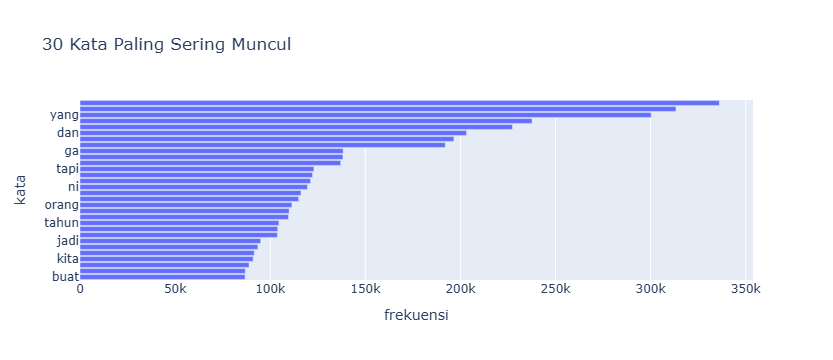

In [5]:
fig1 = px.bar(
    data_kata.to_pandas(),
    x="frekuensi",
    y="kata",
    orientation="h",
    title="30 Kata Paling Sering Muncul"
)
fig1.update_layout(yaxis={"categoryorder": "total ascending"})
fig1.show()

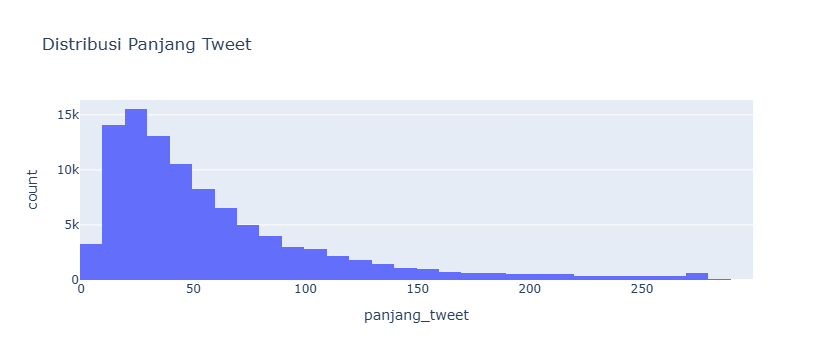

In [6]:
df_panjang = df.with_columns(
    pl.col("tweet").str.len_chars().alias("panjang_tweet")
)

fig2 = px.histogram(
    df_panjang.head(100_000).to_pandas(),
    x="panjang_tweet",
    nbins=40,
    title="Distribusi Panjang Tweet"
)
fig2.show()

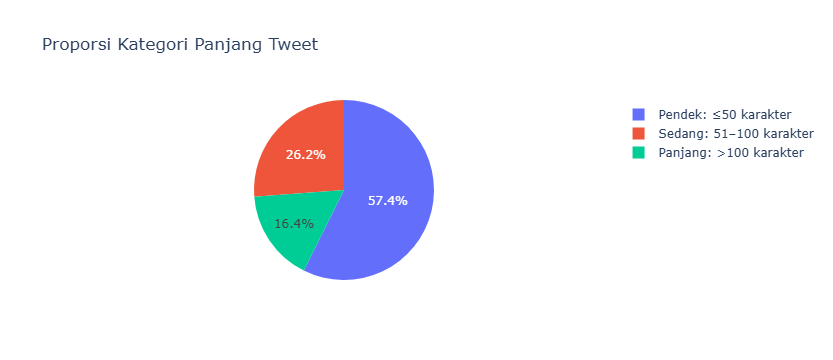

In [7]:
df_kategori = df_panjang.with_columns(
    pl.when(pl.col("panjang_tweet") <= 50)
    .then(pl.lit("Pendek: ≤50 karakter"))
    .when(pl.col("panjang_tweet") <= 100)
    .then(pl.lit("Sedang: 51–100 karakter"))
    .otherwise(pl.lit("Panjang: >100 karakter"))
    .alias("kategori_panjang")
)

ringkasan_panjang = (
    df_kategori.group_by("kategori_panjang")
    .len()
    .sort("len", descending=True)
)

fig3 = px.pie(
    ringkasan_panjang.to_pandas(),
    names="kategori_panjang",
    values="len",
    title="Proporsi Kategori Panjang Tweet"
)
fig3.show()

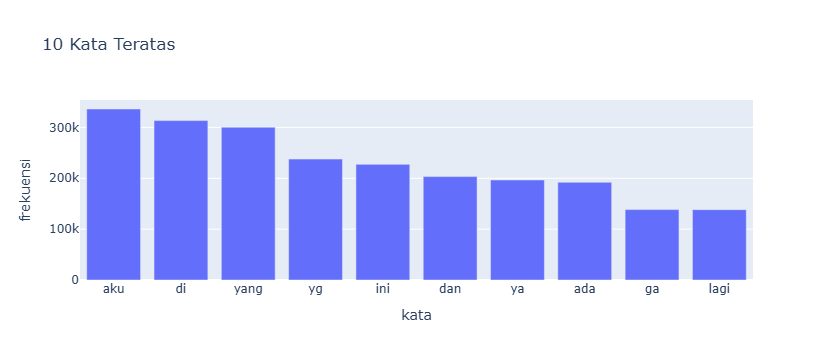

In [8]:
top10 = data_kata.head(10).to_pandas()

fig4 = px.bar(
    top10,
    x="kata",
    y="frekuensi",
    title="10 Kata Teratas"
)
fig4.show()

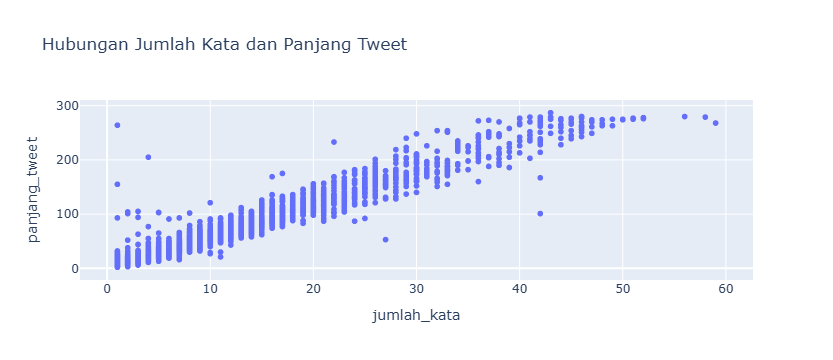

In [9]:
df_hubungan = df.with_columns([
    pl.col("tweet").str.len_chars().alias("panjang_tweet"),
    pl.col("tweet").str.count_matches(r"\S+").alias("jumlah_kata")
])

fig5 = px.scatter(
    df_hubungan.head(5000).to_pandas(),
    x="jumlah_kata",
    y="panjang_tweet",
    title="Hubungan Jumlah Kata dan Panjang Tweet"
)
fig5.show()

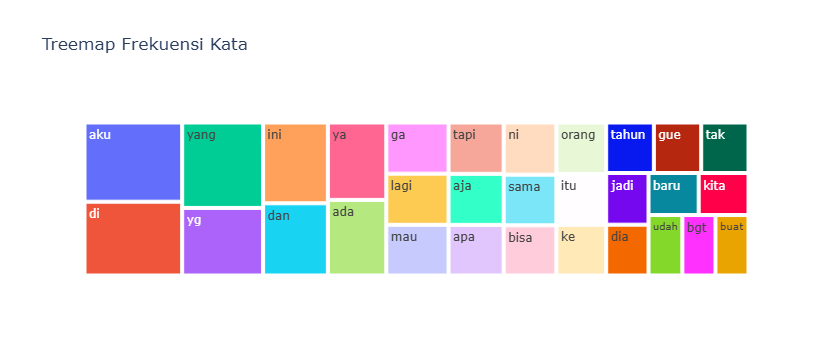

In [10]:
fig6 = px.treemap(
    data_kata.to_pandas(),
    path=["kata"],
    values="frekuensi",
    title="Treemap Frekuensi Kata"
)
fig6.show()